#Лабораторная работа № 7
#Деревья решений и ансамбли на их основе
**Цель работы:**

  1.Освоить принципы построения и настройки дерева решений с помощью sklearn.tree.DecisionTreeClassifier.

  2.Познакомиться с базовыми ансамблевыми методами: бэггинг (Bagging) и бустинг (Boosting).

  3.Сравнить эффективность одиночного дерева и ансамблей на практическом примере.

В этом примере мы используем набор данных о заказах еды онлайн (бинарная классификация) — Online Foods.

#1. Импорт необходимых библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

#2. Загрузка и первичный анализ данных

In [7]:
from google.colab import files
uploaded = files.upload()
df = pd.read_csv('onlinefoods.csv')

if 'Unnamed: 12' in df.columns:
    df = df.drop(columns=['Unnamed: 12'])

print("Размерность данных:", df.shape)
print("Названия признаков:", df.columns.tolist())
print("\nПервые 5 строк:")
print(df.head())
print("\nИнформация о данных:")
print(df.info())
print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nРаспределение целевой переменной (Output):")
print(df['Output'].value_counts())

Saving onlinefoods.csv to onlinefoods (4).csv
Размерность данных: (388, 12)
Названия столбцов: ['Age', 'Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Family size', 'latitude', 'longitude', 'Pin code', 'Output', 'Feedback']

Первые 5 строк:
   Age  Gender Marital Status Occupation  Monthly Income  \
0   20  Female         Single    Student       No Income   
1   24  Female         Single    Student  Below Rs.10000   
2   22    Male         Single    Student  Below Rs.10000   
3   22  Female         Single    Student       No Income   
4   22    Male         Single    Student  Below Rs.10000   

  Educational Qualifications  Family size  latitude  longitude  Pin code  \
0              Post Graduate            4   12.9766    77.5993    560001   
1                   Graduate            3   12.9770    77.5773    560009   
2              Post Graduate            3   12.9551    77.6593    560017   
3                   Graduate            6   12.9473

2.1 Подготовка данных в числовой датасет

In [8]:
X = df.drop(columns=['Output', 'Feedback'])
y = df['Output']

#Кодируем целевую переменную: Yes==1, No==0
le_y = LabelEncoder()
y = le_y.fit_transform(y)
print("Уникальные классы целевой переменной:", np.unique(y))

categorical_cols = X.select_dtypes(include=['object']).columns.tolist()
print("Категориальные признаки:", categorical_cols)

X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
print("Размерность после кодирования:", X_encoded.shape)
print("Признаки:", X_encoded.columns.tolist()[:10], "...")

Уникальные классы целевой переменной: [0 1]
Категориальные признаки: ['Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications']
Размерность после кодирования: (388, 19)
Признаки: ['Age', 'Family size', 'latitude', 'longitude', 'Pin code', 'Gender_Male', 'Marital Status_Prefer not to say', 'Marital Status_Single', 'Occupation_House wife', 'Occupation_Self Employeed'] ...


#3. Разделение данных на обучающую и тестовую выборки

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

print(f"Размер обучающей выборки: {X_train.shape}")
print(f"Размер тестовой выборки: {X_test.shape}")

Размер обучающей выборки: (310, 19)
Размер тестовой выборки: (78, 19)


#4. Построение и оценка базового дерева решений

In [12]:
base_dt = DecisionTreeClassifier(random_state=42)
base_dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [13]:
y_pred_base = base_dt.predict(X_test)

In [14]:
accuracy_base = accuracy_score(y_test, y_pred_base)
print(f"Точность базового дерева на тесте: {accuracy_base:.4f}")

Точность базового дерева на тесте: 0.7821


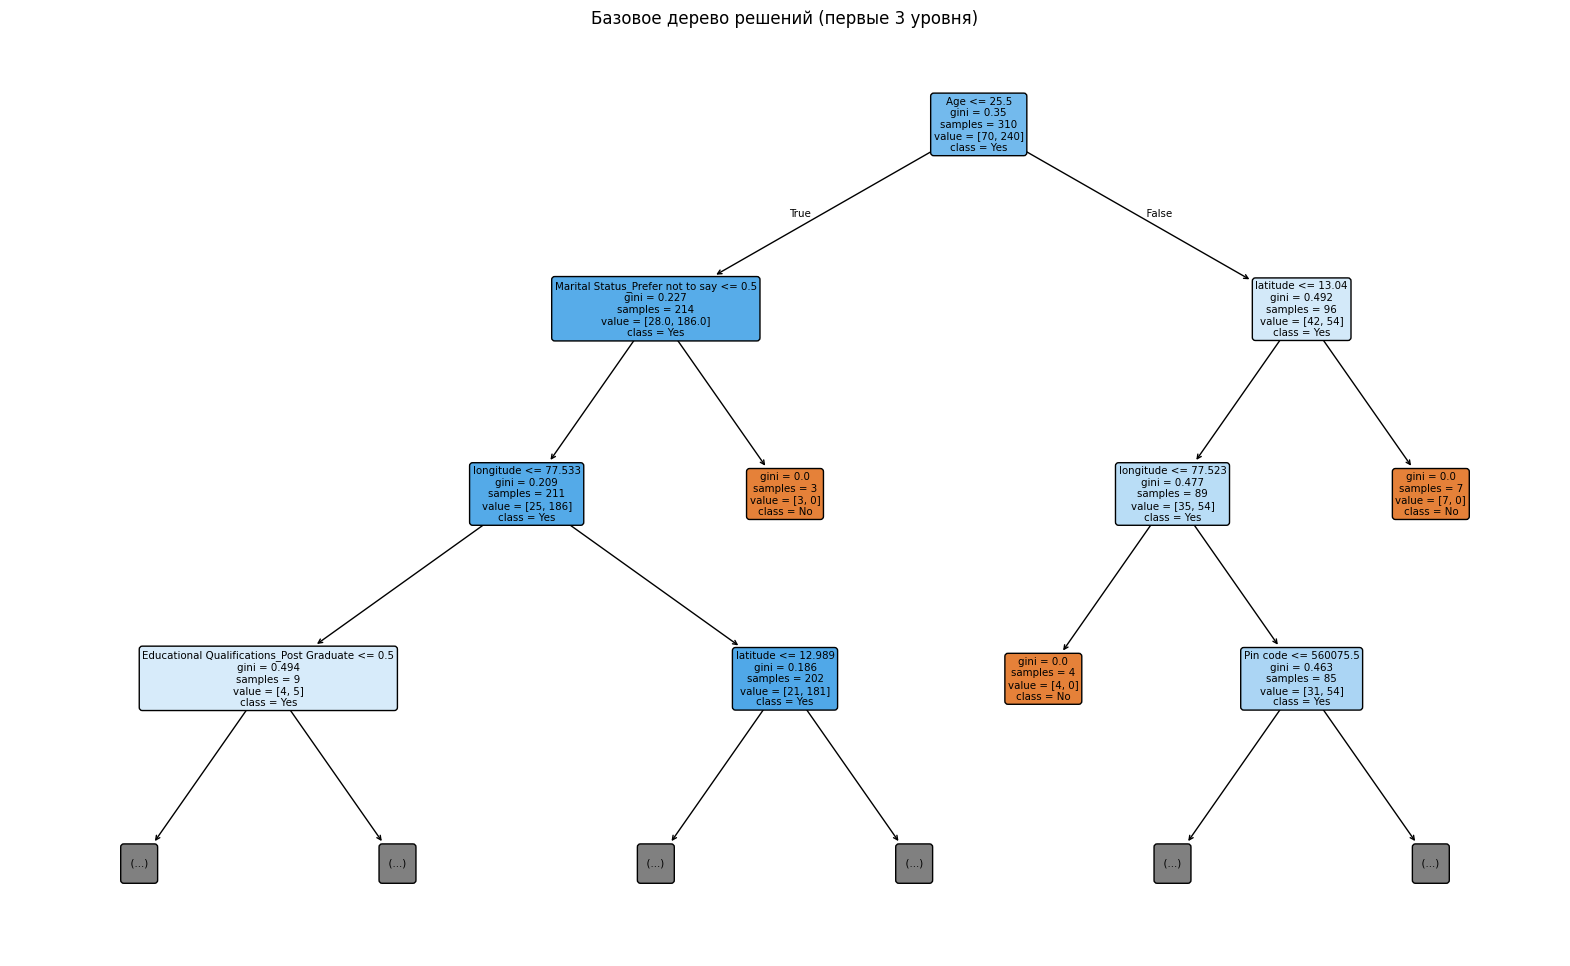

In [15]:
plt.figure(figsize=(20, 12))
plot_tree(base_dt, filled=True, feature_names=X_encoded.columns, class_names=['No', 'Yes'],
          rounded=True, max_depth=3)
plt.title("Базовое дерево решений (первые 3 уровня)")
plt.show()

#6. Борьба с переобучением: настройка гиперпараметров

In [16]:
tuned_dt = DecisionTreeClassifier(max_depth=3, random_state=42)
tuned_dt.fit(X_train, y_train)

y_pred_tuned = tuned_dt.predict(X_test)
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
print(f"Точность настроенного дерева (max_depth=3) на тесте: {accuracy_tuned:.4f}")

Точность настроенного дерева (max_depth=3) на тесте: 0.7821


In [17]:
cv_scores_base = cross_val_score(base_dt, X_encoded, y, cv=5)
cv_scores_tuned = cross_val_score(tuned_dt, X_encoded, y, cv=5)

print(f"Кросс-валидация, базовое дерево: {np.mean(cv_scores_base):.4f} (+/- {np.std(cv_scores_base) * 2:.4f})")
print(f"Кросс-валидация, настроенное дерево: {np.mean(cv_scores_tuned):.4f} (+/- {np.std(cv_scores_tuned) * 2:.4f})")

Кросс-валидация, базовое дерево: 0.7969 (+/- 0.2075)
Кросс-валидация, настроенное дерево: 0.7783 (+/- 0.0604)


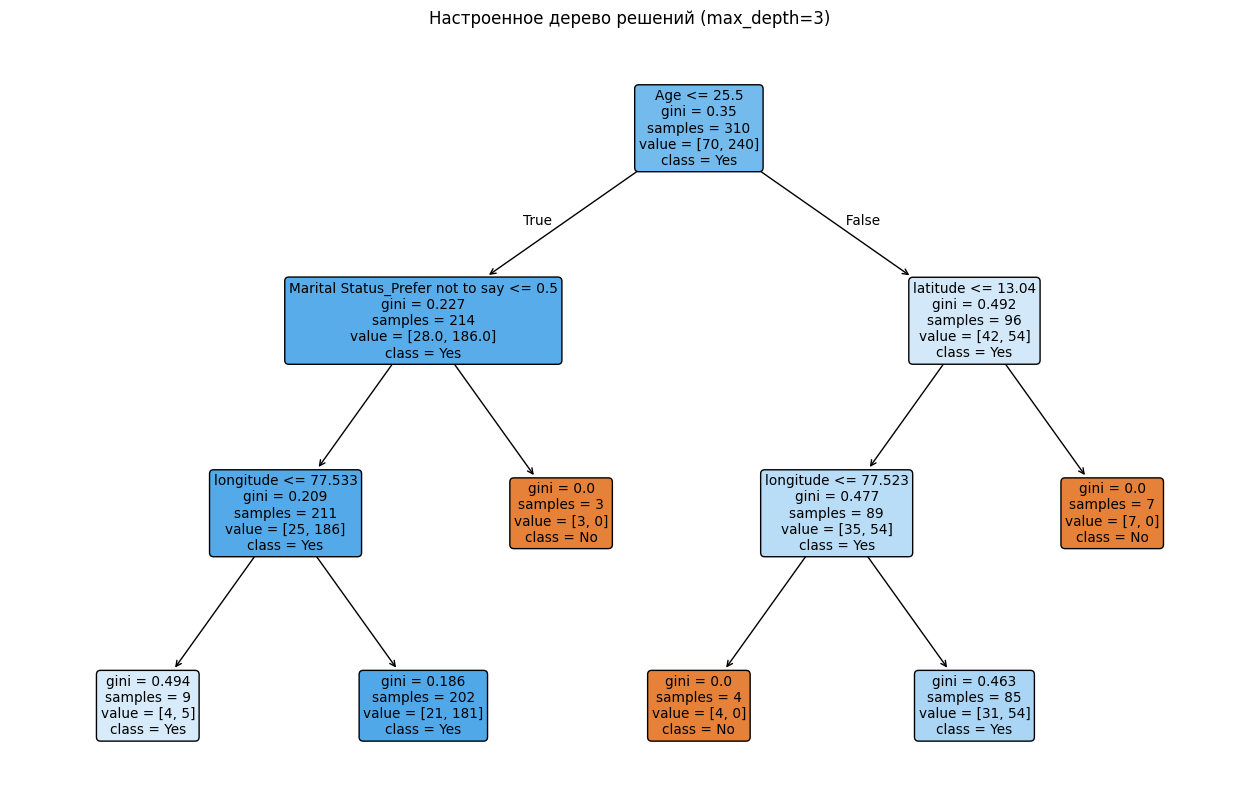

In [18]:
plt.figure(figsize=(16, 10))
plot_tree(tuned_dt, filled=True, feature_names=X_encoded.columns, class_names=['No', 'Yes'], rounded=True)
plt.title("Настроенное дерево решений (max_depth=3)")
plt.show()

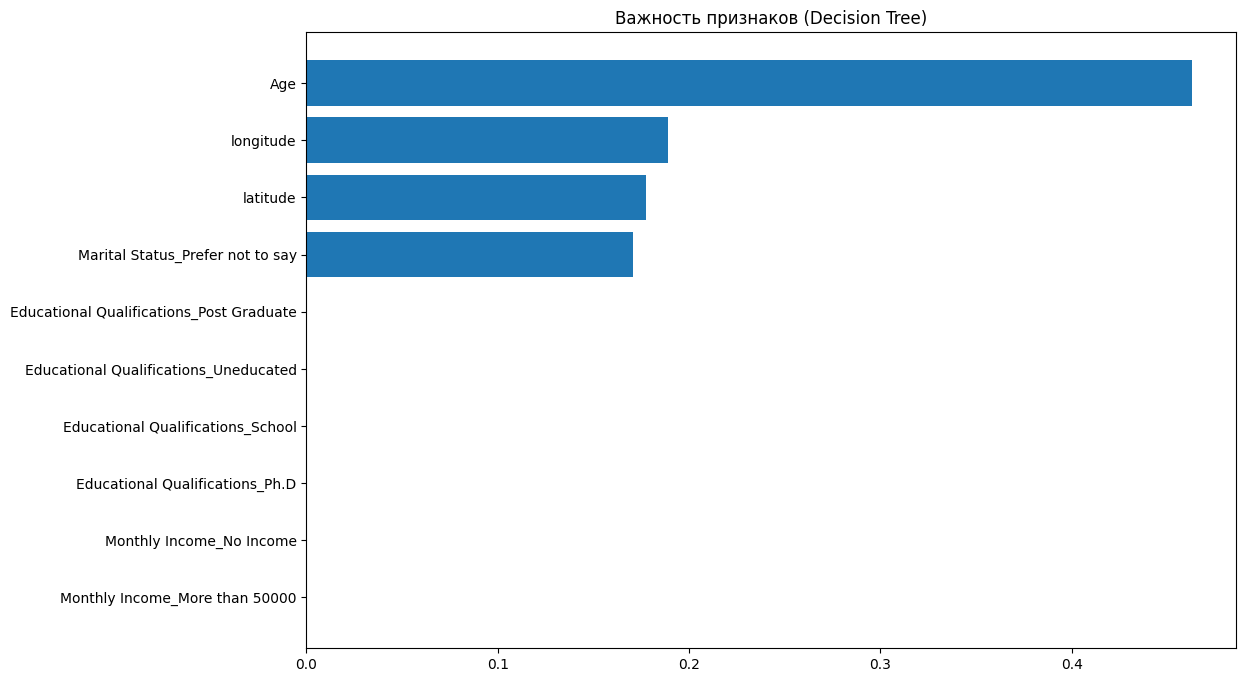

In [19]:
importances = tuned_dt.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 8))
plt.title("Важность признаков (Decision Tree)")
plt.barh(range(10), importances[indices][:10])
plt.yticks(range(10), [X_encoded.columns[i] for i in indices[:10]])
plt.gca().invert_yaxis()
plt.show()

#6. Ансамбли: Случайный лес (Бэггинг)

In [20]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [21]:
y_pred_rf = rf.predict(X_test)
accuracy_rf = accuracy_score(y_test, y_pred_rf)
print(f"Точность Случайного леса на тесте: {accuracy_rf:.4f}")

Точность Случайного леса на тесте: 0.8846


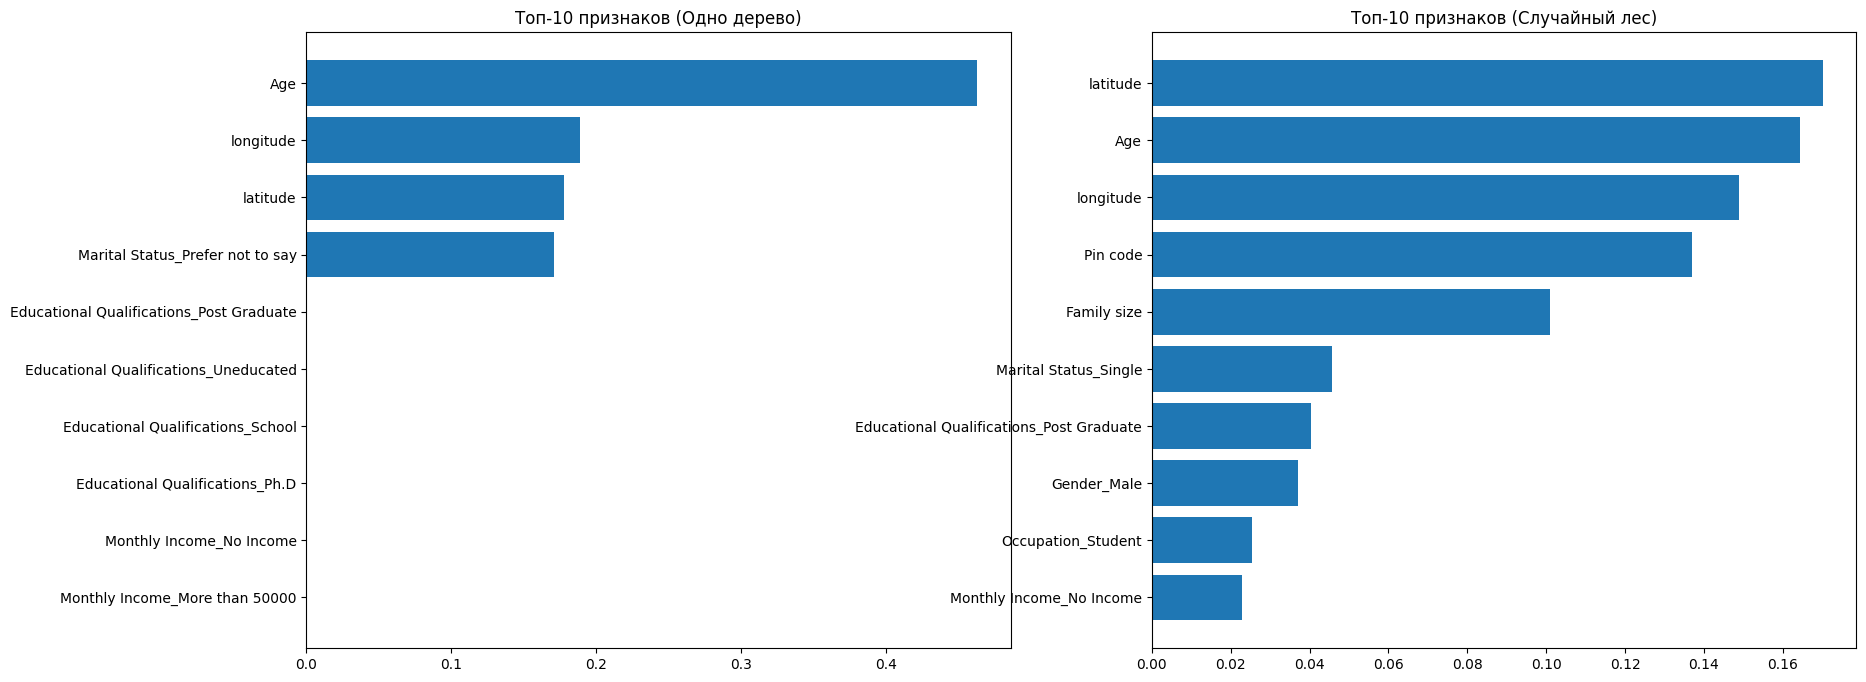

In [22]:
rf_importances = rf.feature_importances_
indices_rf = np.argsort(rf_importances)[::-1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))
ax1.barh(range(10), importances[indices][:10])
ax1.set_title("Топ-10 признаков (Одно дерево)")
ax1.set_yticks(range(10))
ax1.set_yticklabels([X_encoded.columns[i] for i in indices[:10]])
ax1.invert_yaxis()

ax2.barh(range(10), rf_importances[indices_rf][:10])
ax2.set_title("Топ-10 признаков (Случайный лес)")
ax2.set_yticks(range(10))
ax2.set_yticklabels([X_encoded.columns[i] for i in indices_rf[:10]])
ax2.invert_yaxis()
plt.show()

#7. Ансамбли: Градиентный бустинг

In [23]:
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
accuracy_gb = accuracy_score(y_test, y_pred_gb)
print(f"Точность Gradient Boosting на тесте: {accuracy_gb:.4f}")

Точность Gradient Boosting на тесте: 0.8333


#8. Сравнение всех моделей

                     Train Accuracy  Test Accuracy
Base Decision Tree         0.996774       0.782051
Tuned Decision Tree        0.819355       0.782051
Random Forest              0.996774       0.884615
Gradient Boosting          0.954839       0.833333


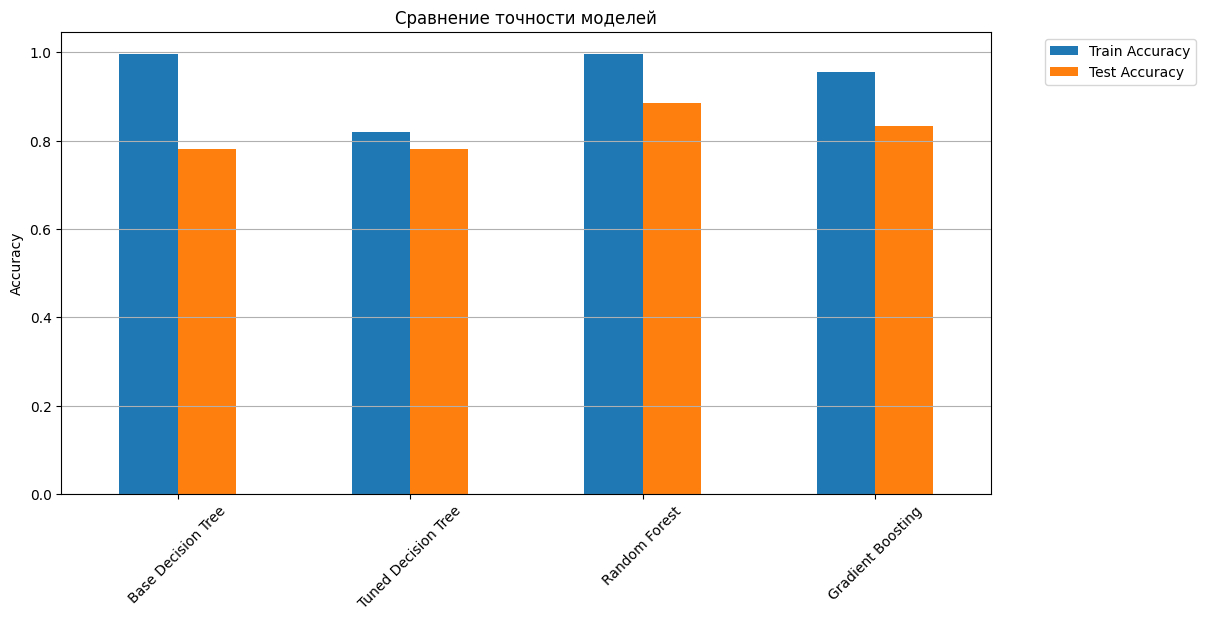

In [24]:
models = {
    'Base Decision Tree': base_dt,
    'Tuned Decision Tree': tuned_dt,
    'Random Forest': rf,
    'Gradient Boosting': gb
}

results = {}
for name, model in models.items():
    if name not in ['Base Decision Tree', 'Tuned Decision Tree']:
        model.fit(X_train, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, model.predict(X_test))
    results[name] = {'Train Accuracy': train_acc, 'Test Accuracy': test_acc}

results_df = pd.DataFrame(results).T
print(results_df)

# Строим bar-plot
results_df[['Train Accuracy', 'Test Accuracy']].plot(kind='bar', figsize=(12, 6))
plt.title("Сравнение точности моделей")
plt.ylabel("Accuracy")
plt.xticks(rotation=45)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(axis='y')
plt.show()

#Самостоятельная работа задание № 1

In [28]:
param_grid = {
    'max_depth': [3, 5, 7, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'criterion': ['gini', 'entropy']
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Лучшие параметры:", grid_search.best_params_)
print(f"Лучшая accuracy (CV): {grid_search.best_score_:.4f}")

best_dt = grid_search.best_estimator_
y_pred_best = best_dt.predict(X_test)
print(f"Accuracy на тесте: {accuracy_score(y_test, y_pred_best):.4f}")

#Сравнение с базовой моделью
base_train_acc = accuracy_score(y_train, base_dt.predict(X_train))
base_test_acc  = accuracy_score(y_test,  base_dt.predict(X_test))

grid_train_acc = accuracy_score(y_train, best_dt.predict(X_train))
grid_test_acc  = accuracy_score(y_test,  best_dt.predict(X_test))

results_df = pd.DataFrame({
    'Base Decision Tree': [base_train_acc, base_test_acc],
    'GridSearchCV':       [grid_train_acc, grid_test_acc]
}, index=['Train Accuracy', 'Test Accuracy'])

print("\n=== Сравнение моделей ===")
print(results_df.round(4))

Лучшие параметры: {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5}
Лучшая accuracy (CV): 0.8161
Accuracy на тесте: 0.7179

=== Сравнение моделей ===
                Base Decision Tree  GridSearchCV
Train Accuracy              0.9968        0.9677
Test Accuracy               0.7821        0.7179
